In [1]:
import tensorflow as tf
tf.config.set_visible_devices([], 'GPU')

2026-11-15 21:26:41.955440: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-15 21:26:42.000780: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-15 21:26:43.137153: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1794765405.059689   27059 gpu_device.cc:2342] Cannot dlopen some GPU libraries.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

In [3]:
x_train = pd.read_csv('../data/processed/x_train.csv')
y_train = pd.read_csv('../data/processed/y_train.csv')
x_val = pd.read_csv('../data/processed/x_val.csv')
y_val = pd.read_csv('../data/processed/y_val.csv')

In [4]:
x_train.shape, y_train.shape, x_val.shape, y_val.shape

((16138, 17), (16138, 1), (4493, 17), (4493, 1))

In [8]:
input = layers.Input(shape=(x_train.shape[1],))
x = layers.Dense(64)(input)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.2)(x)
output = layers.Dense(1)(x)
model = keras.Model(inputs=input, outputs=output)

model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae' , 'mse'])

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath='../models/dense_model.h5',
        save_best_only=True,
        monitor='val_loss'
        )
    ]


In [9]:
hystory = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 13372.0410 - mae: 97.9619 - mse: 13372.0410

505/505 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 13372.0410 - mae: 97.9619 - mse: 13372.0410 - val_loss: 7989.2695 - val_mae: 68.2898 - val_mse: 7989.2695
Epoch 2/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 7429.4819 - mae: 69.9904 - mse: 7429.4819 - val_loss: 14557.4072 - val_mae: 95.8483 - val_mse: 14557.4072
Epoch 3/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 2804.9641 - mae: 39.3023 - mse: 2804.9641 - val_loss: 16725.4277 - val_mae: 104.6805 - val_mse: 16725.4277
Epoch 4/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 1964.4307 - mae: 32.4539 - mse: 1964.4307 - val_loss: 20018.0762 - val_mae: 118.3878 - val_mse: 20018.0762
Epoch 5/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1857.8340 - mae: 31.4544 - mse: 1857.8340 - val_loss: 17560.0371 - val_mae: 108.5674 - val_mse: 17560.0371
Epoch 6/100
504/505 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1849.6166 - mae: 31.3670 - mse: 1849.6166

505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1850.6135 - mae: 31.3799 - mse: 1850.6135 - val_loss: 4685.7305 - val_mae: 56.8574 - val_mse: 4685.7305
Epoch 7/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1820.7965 - mae: 30.9995 - mse: 1820.7965 - val_loss: 5525.7451 - val_mae: 63.4999 - val_mse: 5525.7451
Epoch 8/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1816.5040 - mae: 30.9590 - mse: 1816.5040 - val_loss: 38815.6094 - val_mae: 186.0023 - val_mse: 38815.6094
Epoch 9/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1787.4680 - mae: 30.9047 - mse: 1787.4680 - val_loss: 5542.4575 - val_mae: 64.3179 - val_mse: 5542.4575
Epoch 10/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1785.4143 - mae: 30.5615 - mse: 1785.4143 - val_loss: 19972.9004 - val_mae: 118.2001 - val_mse: 19972.9004
Epoch 11/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1811.6292 - mae: 30.8333 - mse: 1811.6292 - val_loss: 77916.1094 - val_mae: 271.1694 - val_mse: 77916.1094
Epoch 12/10

505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1760.7516 - mae: 30.4085 - mse: 1760.7516 - val_loss: 3872.2305 - val_mae: 50.6653 - val_mse: 3872.2305
Epoch 59/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1740.1859 - mae: 30.1481 - mse: 1740.1859 - val_loss: 554415.6875 - val_mae: 742.7765 - val_mse: 554415.6875
Epoch 60/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1723.0076 - mae: 30.0525 - mse: 1723.0076 - val_loss: 14658.3857 - val_mae: 97.1906 - val_mse: 14658.3857
Epoch 61/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1744.0446 - mae: 30.1426 - mse: 1744.0446 - val_loss: 31688.5723 - val_mae: 170.1156 - val_mse: 31688.5723
Epoch 62/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1741.5219 - mae: 30.2050 - mse: 1741.5219 - val_loss: 98043.0625 - val_mae: 308.6929 - val_mse: 98043.0625
Epoch 63/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1742.1133 - mae: 30.1391 - mse: 1742.1133 - val_loss: 12510.3867 - val_mae: 87.2509 - val_mse: 12510.3867
Ep

505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1759.8796 - mae: 30.3796 - mse: 1759.8796 - val_loss: 3713.9692 - val_mae: 51.9795 - val_mse: 3713.9692
Epoch 78/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1736.5261 - mae: 30.0842 - mse: 1736.5261 - val_loss: 19274.3887 - val_mae: 115.2956 - val_mse: 19274.3887
Epoch 79/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1740.5085 - mae: 30.1570 - mse: 1740.5085 - val_loss: 33666.6680 - val_mae: 174.8030 - val_mse: 33666.6680
Epoch 80/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1742.8857 - mae: 30.1765 - mse: 1742.8857 - val_loss: 5569.3882 - val_mae: 61.6002 - val_mse: 5569.3882
Epoch 81/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1755.1958 - mae: 30.2841 - mse: 1755.1958 - val_loss: 18582.2832 - val_mae: 112.9896 - val_mse: 18582.2832
Epoch 82/100
505/505 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1739.7990 - mae: 30.0984 - mse: 1739.7990 - val_loss: 629164.0625 - val_mae: 791.2698 - val_mse: 629164.0625
Epo

In [15]:
hystory.history.keys()

dict_keys(['loss', 'mae', 'mse', 'val_loss', 'val_mae', 'val_mse'])

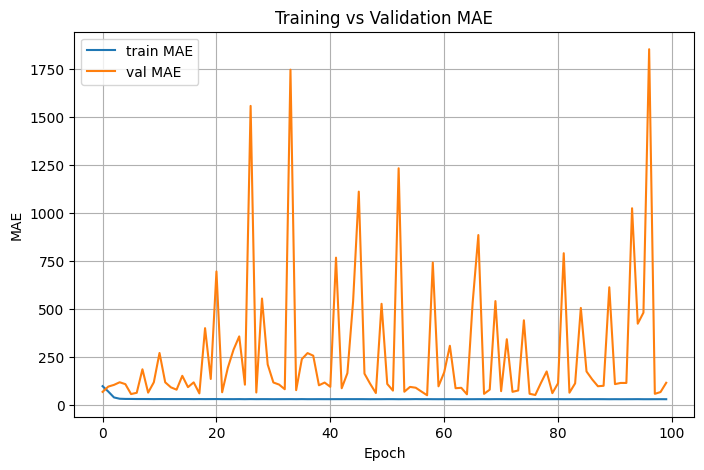

In [22]:
# elbow method
plt.figure(figsize=(8, 5))
plt.plot(hystory.history["mae"], label="train MAE")
plt.plot(hystory.history["val_mae"], label="val MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training vs Validation MAE")
plt.legend()
plt.grid(True)
plt.show()

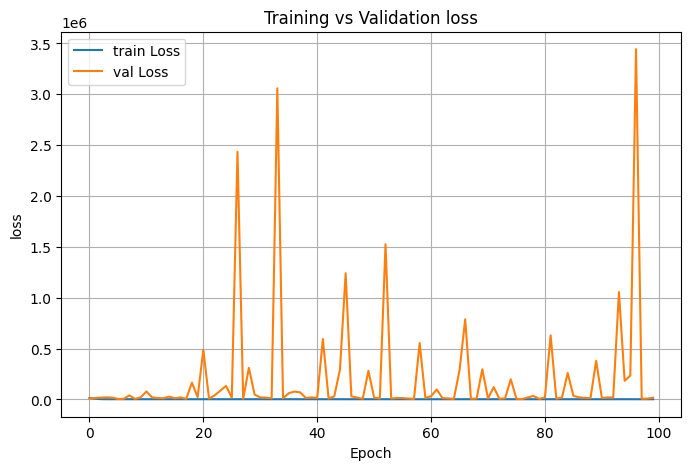

In [24]:
plt.figure(figsize=(8, 5))
plt.plot(hystory.history["loss"], label="train Loss")
plt.plot(hystory.history["val_loss"], label="val Loss")
plt.xlabel("Epoch")
plt.ylabel("loss")
plt.title("Training vs Validation loss")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
model = keras.models.load_model("../models/dense_model.h5")

In [27]:
model.evaluate(x_val , y_val)

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 3713.9692 - mean_absolute_error: 51.9795 - mean_squared_error: 3713.9692 


[3713.96923828125, 51.97951889038086, 3713.96923828125]